# Tutorial: C3-WM's communication model

> Agents in FindGoal send each other codebook tokens over a ray-traced wireless channel, with channel inversion from a predicted channel gain.

The communication model of C3-WM (Section III-B and IV-B of the paper), built from comm-core's components and run
in a stable-marl environment.

| the paper | here |
|---|---|
| a fixed communication graph, a TDMA sub-slot per directed link | `CommunicationWrapper` with a full mesh: one round per step, links do not interfere |
| a c × c map of codebook tokens, K = 256, ⌈log₂K⌉ bits per token | `message_fn` returning 49 `uint8` indices, `IndexCodec(256)` |
| BPSK, block fading, AWGN, coherent ML detection (eqs. 4–5) | `LinkLevelChannel(UncodedChain(IndexCodec(256), BPSK()))` |
| channel gains from Sionna RT at 2.4 GHz, every pair of traversable cells | `RayTracedFading`, from a scene exported by `stable_marl.envs.multigrid.sionna_export` and traced with comm-core's `trace_paths` |
| power from a gain predicted from the last L̃ gains, sent only within ρ_max (eqs. 23–27) | `PredictedChannelInversion`, with a predictor from `fit_gain_predictor` |
| the predictor's training set D_channel (eq. 22) | gains recorded along random rollouts, `gain_windows` |
| (proposed) the gain looked up in the map, where the receiver can have moved since its last report | `MapChannelInversion` |

The 7 × 7 token map comes from MsgNet in C3-WM. Here, a stand-in with the same shape is used: the 7 × 7 grid of
object indices in each agent's view (`obs['image'][..., 0]`). The communication model does not depend on what the
tokens mean.

In [ ]:
import json
import os
import tempfile

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np

import stable_marl
from comm_core import (BPSK, ChannelInversion, FixedPower, IndexCodec, LinkLevelChannel, MapChannelInversion,
                       PredictedChannelInversion, RayTracedFading, UncodedChain, fit_gain_predictor, gain_windows)
from stable_marl.comm import CommunicationWrapper, multigrid_positions, node_id
from stable_marl.envs.multigrid.sionna_export import SceneConfig, export_scene, grid_to_world

## The environment

FindGoal on a 9 × 9 grid, 2 agents. As in the paper, the layout (walls, rooms) is the same in every episode: every
episode is reset with the same layout seed, and the agents' paths differ through their actions.

In [ ]:
LAYOUT_SEED = 0
make_env = lambda: gym.make('MultiGrid-FindGoal-15x15-v0', agents=2, size=9, num_obstacles=0, max_episode_steps=60)
env = make_env()
env.reset(seed=LAYOUT_SEED)
grid = env.unwrapped.grid
CELLS = [(x, y) for x in range(grid.width) for y in range(grid.height) if (o := grid.get(x, y)) is None or o.can_overlap()]
print(f'{len(CELLS)} traversable cells')

39 traversable cells


## The channel table, ray-traced with Sionna RT

The layout is exported as a Sionna RT scene: walls of concrete and brick, with 2 m cells. Then the paths between
the antennas (1.5 m high) at the centres of every pair of traversable cells are traced at 2.4 GHz, with up to 5
bounces. With fewer bounces, some pairs in different rooms get no path at all.

This needs Sionna RT, so the cell doesn't run with the tests or the docs (`#| eval: false`). Its output is from running it
with Sionna 2.2. It saves the table, and the rest of this page loads the
saved file.

In [ ]:
#| eval: false
import sionna.rt as rt
from comm_core import trace_paths

config = SceneConfig()
scene_dir = tempfile.mkdtemp()
export_scene(env, scene_dir, config=config, frequency=2.4e9)
scene = rt.load_scene(os.path.join(scene_dir, 'scene.xml'))
scene.frequency = 2.4e9
points = np.array([grid_to_world(x, y, grid.width, grid.height, config, config.antenna_height) for x, y in CELLS], float)
paths = trace_paths(scene, points, points, max_depth=5)          # up to 5 bounces: paths between all rooms
H = paths['a'].sum(-1).T                                     # H[rx, tx] at the carrier, the sum of the paths
np.savez_compressed('c3wm_findgoal_channel.npz', H=H, cells=np.array(CELLS))
print(f"traced {len(CELLS)} x {len(CELLS)} cell pairs, up to {paths['a'].shape[-1]} paths each")

traced 39 x 39 cell pairs, up to 109 paths each


path gain between cells: -148 to -41 dB; 1 directed pairs without any path


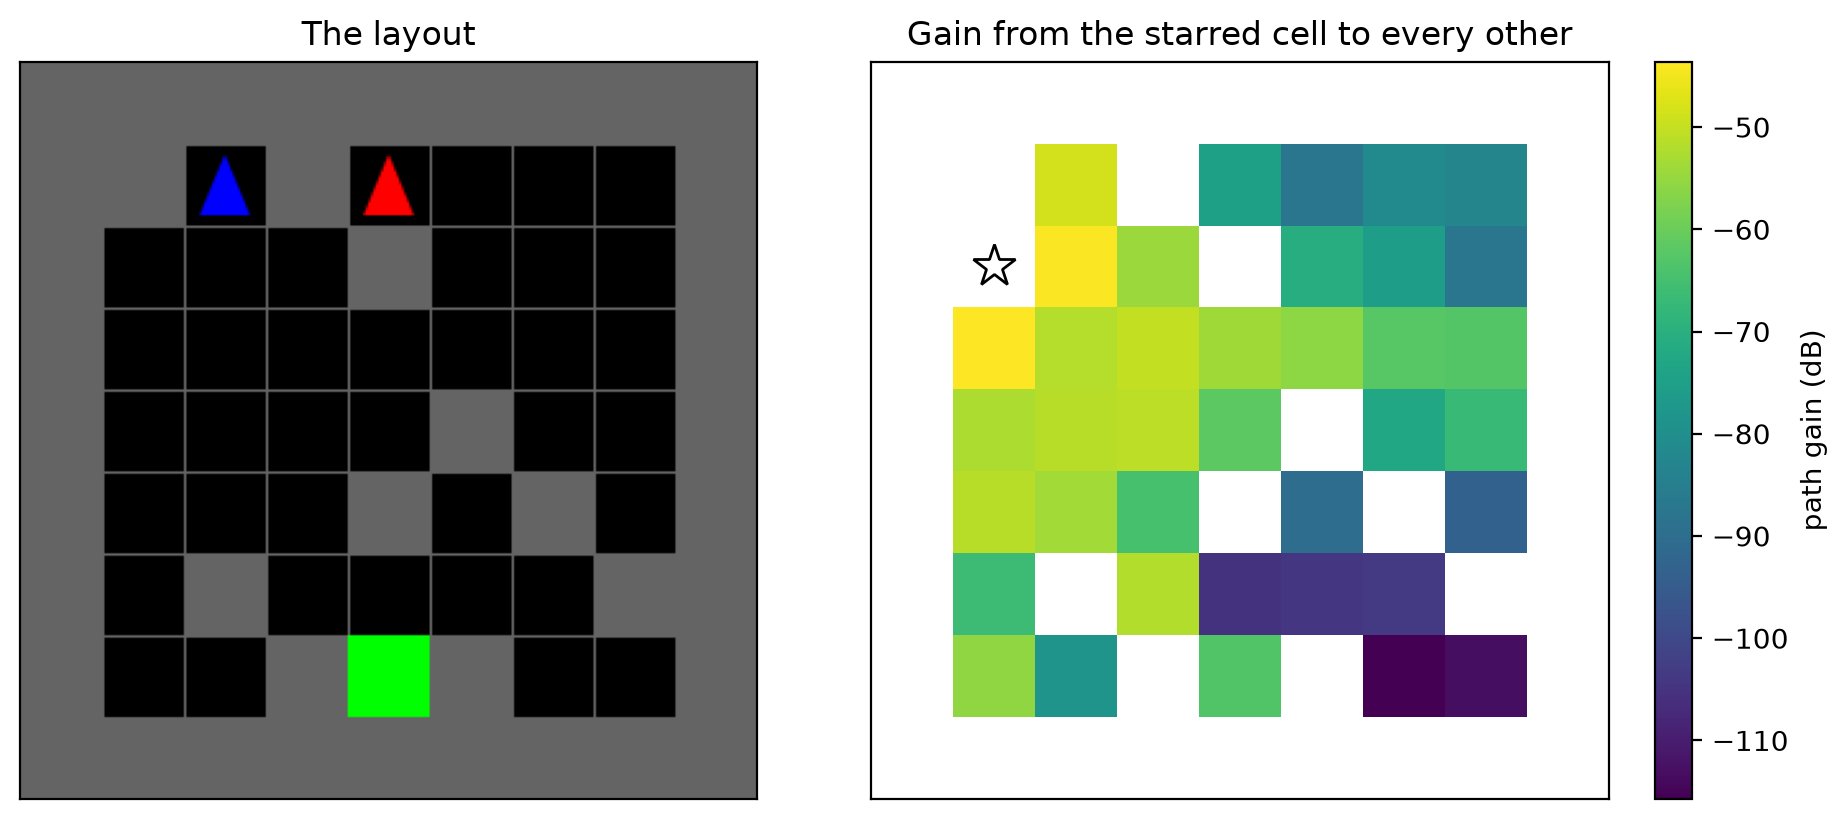

In [ ]:
table = np.load('c3wm_findgoal_channel.npz')
H, cells = table['H'], [tuple(c) for c in table['cells']]
assert cells == CELLS
fading = RayTracedFading(H, cells)                         # agents' positions are their cells
off = ~np.eye(len(cells), dtype=bool)
linked = off & (H != 0)
gain_db = 10 * np.log10(np.abs(H[linked]) ** 2)
print(f'path gain between cells: {gain_db.min():.0f} to {gain_db.max():.0f} dB; {(off & (H == 0)).sum()} directed pairs without any path')

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
axes[0].imshow(env.unwrapped.get_frame(highlight=False) if hasattr(env.unwrapped, 'get_frame') else env.render())
axes[0].set(title='The layout', xticks=[], yticks=[])
src = cells.index(min(cells))                                # a transmitter (the star)
img = np.full((grid.height, grid.width), np.nan)
for (x, y), g in zip(cells, 10 * np.log10(np.abs(H[:, src]) ** 2 + 1e-30)):
    img[y, x] = g
img[cells[src][1], cells[src][0]] = np.nan
im = axes[1].imshow(img, cmap='viridis')
axes[1].plot(*cells[src], 'w*', ms=16, mec='k')
fig.colorbar(im, ax=axes[1], label='path gain (dB)')
axes[1].set(title='Gain from the starred cell to every other', xticks=[], yticks=[])
plt.tight_layout()

## The predictor's training set

The transmitter does not know the current gain. It predicts it from the link's last L̃ = 4 gains. The training set
D_channel (eq. 22) holds the gain of both directed links at every step of recorded episodes, here random
rollouts in the same layout.

In [ ]:
HISTORY = 4
AGENTS = [node_id(a) for a in range(2)]

def rollout(seed, steps=60):
    "One random rollout: per step, each agent's cell and heading."
    env = make_env()
    env.reset(seed=LAYOUT_SEED)
    rng = np.random.default_rng(seed)
    out = []
    for _ in range(steps):
        u = env.unwrapped
        out.append(([tuple(int(v) for v in p) for p in multigrid_positions(u)], [int(a.state.dir) for a in u.agents]))
        env.step({a: int(rng.integers(env.action_space[a].n)) for a in range(2)})
    return out

def link_gain(tx, rx):
    return max(fading.gain_between(tx, rx), 1e-15)                       # a pair without any path: -150 dB

def rollout_gains(seed):
    "The gains |h|² of the two directed links along one random rollout."
    traj = rollout(seed)
    return [[link_gain(cells[j], cells[i]) for cells, _ in traj] for j, i in ((0, 1), (1, 0))]

training = [g for seed in range(150) for g in rollout_gains(seed)]   # a pair without any path: -150 dB
psi = fit_gain_predictor(training, history=HISTORY)                   # least squares on |h|², as in eq. 24
psi_db = fit_gain_predictor(training, history=HISTORY, domain='db')   # the same, on the gains in dB
X, y = map(np.concatenate, zip(*(gain_windows(g, HISTORY) for g in training)))
for name, p in (('fitted on |h|²', psi), ('fitted in dB', psi_db), ('last gain', lambda past: past[0])):
    err = 10 * np.log10(np.maximum([p(x) for x in X], 1e-30)) - 10 * np.log10(y)
    print(f'{name:15s} prediction error: mean {err.mean():+.1f} dB, spread (std) {err.std():.1f} dB')

fitted on |h|²  prediction error: mean +14.8 dB, spread (std) 17.4 dB
fitted in dB    prediction error: mean +0.0 dB, spread (std) 6.4 dB
last gain       prediction error: mean -0.4 dB, spread (std) 6.6 dB


## Comparing the predictors

The transmitter's problem (eq. 14) is to reach the target SNR Γ with the least power. A predictor that
underestimates gains reaches the target more often, but spends more. So each predictor runs with a margin (a
factor on its power), swept. It is judged by the mean power it needs, relative to perfect CSI's, to reach Γ on 90%,
95% or 99% of the transmissions that perfect CSI can serve within ρ_max. Missed links count as failures, and power
spent on links that cannot be served counts as cost.

Besides the history predictors, two use a map:

* **map, receiver's last cell:** the ray-traced table, looked up at the transmitter's cell and the cell the
  receiver reported with its last message.
* **map, robust:** the receiver also reports its heading, and the table is looked up at the weakest cell the
  receiver can have reached since: where it was, or one cell ahead. MultiGrid agents turn or move forward.

The parameters: Γ = 7 dB, noise σ² = −94 dBm, ρ_max = 100 mW, and 40 test episodes of random moves.

In [ ]:
SNR_TARGET_DB, NOISE_W, MAX_POWER_W = 7.0, 10 ** ((-94 - 30) / 10), 0.1
SNR_TARGET = 10 ** (SNR_TARGET_DB / 10)
DIRS = [(1, 0), (0, 1), (-1, 0), (0, -1)]                               # MultiGrid: right, down, left, up

def reachable(cell, heading):
    "Where an agent that reported `cell` and `heading` can be one step later: there, or one cell ahead."
    return [tuple(cell), (cell[0] + DIRS[heading][0], cell[1] + DIRS[heading][1])]

estimates = {k: [] for k in ('last gain', 'linear on |h|² (paper)', 'linear in dB', "map, receiver's last cell", 'map, robust')}
truth = []
for seed in range(1000, 1040):
    traj = rollout(seed)
    for j, i in ((0, 1), (1, 0)):
        g = [link_gain(cells[j], cells[i]) for cells, _ in traj]
        for t in range(HISTORY, len(traj)):
            past = np.array(g[t - HISTORY:t][::-1])
            tx, (rx_before, heading) = traj[t][0][j], (traj[t - 1][0][i], traj[t - 1][1][i])
            near = [c for c in reachable(rx_before, heading) if c in fading.index and c != tx] or [rx_before]
            truth.append(g[t])
            estimates['last gain'].append(past[0])
            estimates['linear on |h|² (paper)'].append(max(psi(past), 0.0))
            estimates['linear in dB'].append(psi_db(past))
            estimates["map, receiver's last cell"].append(link_gain(tx, rx_before) if tx != rx_before else min(link_gain(tx, c) for c in near))
            estimates['map, robust'].append(min(link_gain(tx, c) for c in near))
truth = np.array(truth)
estimates = {k: np.array(v) for k, v in estimates.items()}
servable = SNR_TARGET * NOISE_W / truth <= MAX_POWER_W
perfect_power = np.where(servable, SNR_TARGET * NOISE_W / truth, 0.0).mean()

def outcome(estimate, margin_db):
    "(share of the servable transmissions reaching Γ, mean power relative to perfect CSI's)."
    power = SNR_TARGET * NOISE_W * 10 ** (margin_db / 10) / np.maximum(estimate, 1e-30)
    sent = power <= MAX_POWER_W
    reached = sent & (power * truth / NOISE_W >= SNR_TARGET * (1 - 1e-9))
    return reached[servable].mean(), np.where(sent, power, 0.0).mean() / perfect_power

margins = np.arange(-6, 30.01, 0.1)
curves = {k: np.array([outcome(e, m) for m in margins]) for k, e in estimates.items()}

def power_for(k, share):
    ok = curves[k][:, 0] >= share
    return curves[k][ok, 1].min() if ok.any() else np.inf

def margin_for(k, share):
    ok = curves[k][:, 0] >= share
    return margins[ok][np.argmin(curves[k][ok, 1])]

print(f"{'':26s} {'error (dB): mean':>16s} {'spread':>7s} | power to reach Γ on 90 / 95 / 99% (× perfect CSI)")
for k, e in estimates.items():
    err = 10 * np.log10(np.maximum(e, 1e-30) / truth)
    err = err[e > 0]                                                   # predictions clipped to 0: no dB error
    print(f'{k:26s} {err.mean():+16.1f} {err.std():7.1f} | ' +
          '  '.join(f'{power_for(k, q):5.1f}' if np.isfinite(power_for(k, q)) else '  -  ' for q in (0.9, 0.95, 0.99)))

                           error (dB): mean  spread | power to reach Γ on 90 / 95 / 99% (× perfect CSI)
last gain                              -0.4     6.6 |   1.2    -      -  
linear on |h|² (paper)                +13.4    12.1 |   2.4    2.4    -  
linear in dB                           -0.2     6.4 |   1.0    -      -  
map, receiver's last cell              -0.2     4.8 |   0.7    -      -  
map, robust                            -2.3     5.8 |   0.8    0.8    -  


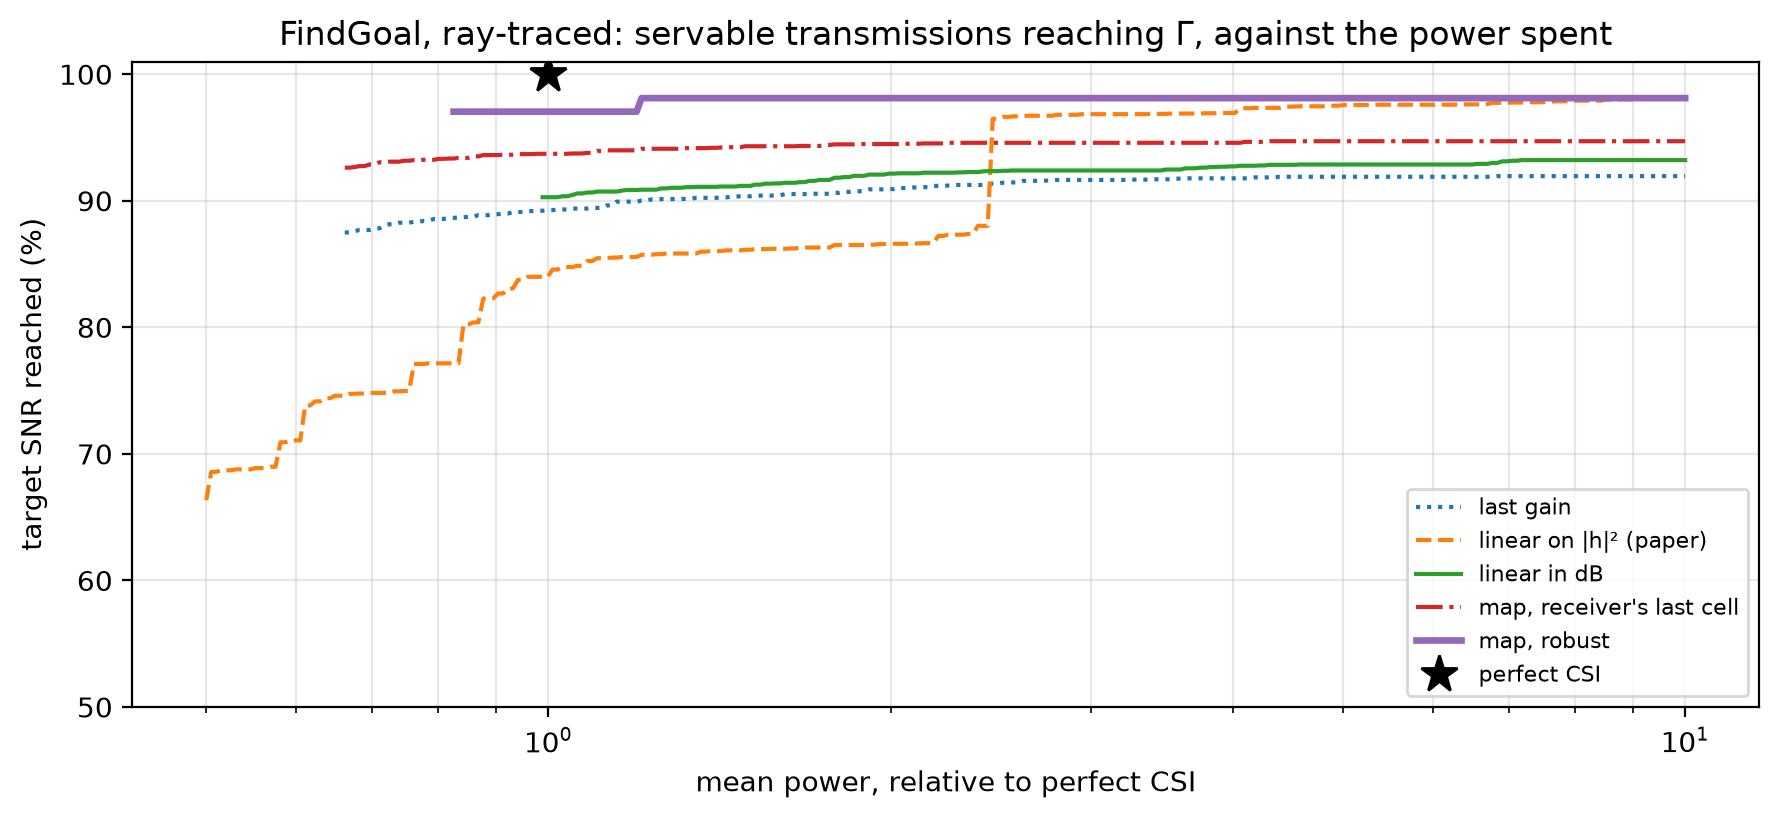

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4.2))
powers = np.geomspace(0.5, 10, 300)
for k, ls in zip(estimates, (':', '--', '-', '-.', '-')):
    best = [curves[k][curves[k][:, 1] <= q, 0].max() if (curves[k][:, 1] <= q).any() else np.nan for q in powers]
    ax.plot(powers, 100 * np.array(best), ls, lw=2.4 if k == 'map, robust' else 1.5, label=k)
ax.plot(1, 100, 'k*', ms=14, label='perfect CSI')
ax.set(xscale='log', ylim=(50, 101), xlabel='mean power, relative to perfect CSI', ylabel='target SNR reached (%)',
       title='FindGoal, ray-traced: servable transmissions reaching Γ, against the power spent')
ax.grid(alpha=0.3, which='both'); ax.legend(fontsize=8, loc='lower right')
plt.tight_layout()

## Through the wrapper

The same comparison, run for real with comm-core's power controls through `CommunicationWrapper`. Each transmitter
runs at the margin where it reaches Γ on 90% of the servable transmissions with the least power:

* **perfect CSI:** `ChannelInversion`.
* **the paper's predictor:** `PredictedChannelInversion` with the fit on `|h|²`.
* **map, robust:** `MapChannelInversion`. It reads the agents' cells from the channel and their headings from the
  environment, and uses them one step late, as reports. It uses the paper's predictor until a receiver has
  reported.

The power controls keep their own histories and reports. Each episode starts them over.

In [ ]:
tokens = lambda env, agent, obs: obs[agent]['image'][..., 0].astype(np.uint8).reshape(-1)     # stand-in for MsgNet

def make_power(name, env):
    if name == 'perfect CSI':
        return ChannelInversion(SNR_TARGET_DB, max_power=MAX_POWER_W)
    paper = PredictedChannelInversion(psi, HISTORY, SNR_TARGET_DB, MAX_POWER_W, fallback_power=MAX_POWER_W / 10,
                                      margin_db=margin_for('linear on |h|² (paper)', 0.9))
    if name == "the paper's predictor":
        return paper
    headings = lambda: {node_id(a): int(agent.state.dir) for a, agent in enumerate(env.unwrapped.agents)}
    return MapChannelInversion(fading, reachable=reachable, states=headings, target_snr_db=SNR_TARGET_DB,
                               max_power=MAX_POWER_W, margin_db=margin_for('map, robust', 0.9), fallback=paper)

def evaluate(name, episodes=range(1000, 1040), steps=60):
    env = make_env()
    channel = LinkLevelChannel(UncodedChain(IndexCodec(256), BPSK()), fading=fading, noise_power=NOISE_W)
    wrapped = CommunicationWrapper(env, message_fn=tokens, message_dim=49, channel=channel)
    channel.power_control = make_power(name, wrapped)
    reached, power, token_errors = [], [], []
    for seed in episodes:
        rng = np.random.default_rng(seed)
        obs, _ = wrapped.reset(seed=LAYOUT_SEED)
        for t in range(steps):
            obs, *_ = wrapped.step({a: int(rng.integers(wrapped.action_space[a].n)) for a in range(2)})
            for r in wrapped.comm.last_results:
                if t < HISTORY:
                    continue
                g = 10 ** (r.metadata['channel_gain_db'] / 10)
                power.append(r.metadata['tx_power'])
                if SNR_TARGET * NOISE_W / g <= MAX_POWER_W:
                    reached.append(r.success and r.snr_db >= SNR_TARGET_DB - 1e-9)
            for i in range(2):
                if t >= HISTORY and obs[i]['message_mask'][1 - i]:
                    token_errors.append(np.mean(obs[i]['messages'][1 - i] != tokens(None, 1 - i, obs)))
    return np.mean(reached), np.mean(power) / perfect_power, np.mean(token_errors)

print(f"{'':22s} {'Γ reached':>10s} {'power':>7s} {'tokens wrong':>13s}")
results = {}
for name in ('perfect CSI', "the paper's predictor", 'map, robust'):
    results[name] = evaluate(name)
    r = results[name]
    print(f'{name:22s} {100 * r[0]:9.1f}% {r[1]:6.2f}x {100 * r[2]:12.2f}%')

                        Γ reached   power  tokens wrong
perfect CSI                100.0%   1.00x         0.63%
the paper's predictor       96.4%   2.42x        10.23%
map, robust                 97.1%   0.82x         0.44%


* **The paper's predictor** (fitted on `|h|²`) is biased and spread widely. To reach Γ reliably it needs a large
  margin, so it spends far more power than perfect CSI. It also keeps sending to links it cannot serve, which is
  where its wrong tokens come from.
* **The history predictors** (last gain, or a linear fit in dB) reach Γ 90% of the time, but not 95%. Their errors
  have too wide a spread for a margin to cover within ρ_max.
* **The robust map lookup** reaches Γ on nearly every transmission it sends, with almost no wrong tokens, at about
  a third of the paper's power. Its errors are one-sided: the receiver is at the cell it reported or one cell
  ahead, and it takes the weaker of the two.
* **Below 1× perfect CSI's power?** Perfect CSI serves every servable link, including the most expensive ones near
  ρ_max, which dominate the mean power. The robust lookup does not send when the weaker cell would need more than
  ρ_max. It gives up a few of the costliest links, and so reaches 95–97% for less power, but not 99%.
* **What it costs:** each message also carries the sender's cell and heading (about 8 bits on 392), and the
  transmitter needs the ray-traced table, which C3-WM computes anyway.
* **When reports are lost:** this assumes every receiver's last report arrived. A lost message makes the report
  older, so more cells become reachable: the prediction stays robust if `reachable` accounts for the extra steps,
  at a higher power.

## Using the tokens

What `CommunicationWrapper` puts in agent `i`'s observation is what the world model's predictor consumes:

* `messages[j]` holds the 49 tokens received from agent `j`, possibly with wrong tokens.
* `message_mask[j]` is `False` when nothing arrived (δ = 0, eq. 27).

From there, the learning code follows Section III-C of the paper:

```python
received = [codebook[obs[i]['messages'][j].astype(int)].mean(0)        # eqs. (7)-(9): look up, average the tokens
            for j in range(num_agents) if obs[i]['message_mask'][j]]
e_i = aggregate(received) if received else e_oov                      # eq. (10); nothing received: e_OOV
```

**Changing the model:** each part can be swapped on its own.

* **Positions:** a different layout or a bigger grid takes a new table (export the scene, then `trace_paths`).
* **Channel model:** a fading channel (`RayleighFading`) instead of the ray-traced table.
* **Coding:** coded transmission instead of BPSK, e.g. `LinkLevelChannel(NRChain())`, Sionna PHY's 5G NR LDPC.
* **Interference:** a channel with `interference=True` and a protocol (TDMA, ALOHA) instead of orthogonal sub-slots.

In [ ]:
assert np.isfinite(power_for('map, robust', 0.95))
assert power_for('map, robust', 0.95) < power_for('linear on |h|² (paper)', 0.95)
assert abs(results['map, robust'][0] - outcome(estimates['map, robust'], margin_for('map, robust', 0.9))[0]) < 0.05